In [12]:
import pandas as pd
import matplotlib.pyplot as plt

In [13]:
data = pd.read_excel("anomalies_corrected_data.xlsx", sheet_name="Data")

# Understanding each feature

### Meaning of features

step - index of data point

rat_id - radio access technology id, 23 could be 4G and 5G, 6 means 4G

eci_nci - ECI (E-UTRAN Cell Identity) is a 28-bit cell identifier used in 4G LTE networks,
NCI (NR Cell Identity) is a 36-bit cell identifier used in 5G New Radio (NR) networks.
If eci can be translated into less then or equal 28-bit then eci else nci

network - 4G or 5G technology

timestamp - when this happened. Measured with 1 microsecond resolution and in UTC timezone. 
(example: 2025-12-24T00:11:07.044096Z - 2025-12-24 year/month/day, 00:11:07.044096Z - hours/minutes/seconds)

latitude - cell latitude coordinate

longitude - cell longitude coordinate

geometry_type - ARC means cell covers a sector, CIRCLE means cell covers 0 - 360 degrees

start_angle - coverage sector start angle (for circle it is always 0)

end_angle - coverage sector end angle (for circle it is always 360)

outer_radius - defines the accuracy of the location in meters

inner_radius - unimportant, dont know what, but in our dataset always 0

cell_updated_flag - dont know what, depends on device_interface_type

device_interface_type - what interface the cell implements (S1_MME for 4G and N1, N11 for 5G)

server - node that processed that event

application_name - protocols

message_name - event name

apn_name - application name - ims, ota or pda





In [14]:
#check whether S1_MME is ONLY for 4G and N1, N11 are ONLY for 5G
def assumption1():
    check1 = len(data[data["device_interface_type"] == "S1_MME"]["device_interface_type"].value_counts())
    check2 = len(data[data["device_interface_type"] == "N1"]["device_interface_type"].value_counts())
    check3 = len(data[data["device_interface_type"] == "N11"]["device_interface_type"].value_counts())

    if all([x == 1 for x in [check1, check2, check3]]):
        print("Correct assumption")
#assumption1()

#check whether each cell is tied with exactly one location
def assumption2():
    flag = True
    for i in data["eci_nci"]: 
        counts = data[data["eci_nci"] == i][["longitude", "latitude"]].value_counts()
        if len(counts) > 1:
            flag = False
    if flag:
        print("Correct assumption")
#assumption2()

In [38]:
#check if there exist Nan or None or missing values, return list of feature/features if there is
def faulty_feature_values():
    faulty_features = []
    for feature in data.columns:
        if data[feature].isna().sum() > 0:
            faulty_features.append(feature)
    if len(faulty_features) > 0:
        print("Missing values in these features: ", ", ".join(faulty_features))
    return faulty_features
faulty_feature_values()

Missing values in these features:  cell_updated_flag, apn_name


['cell_updated_flag', 'apn_name']

Missing values in these features:  cell_updated_flag, apn_name


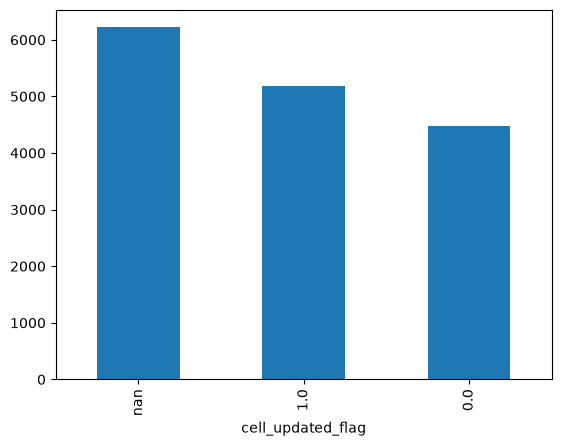

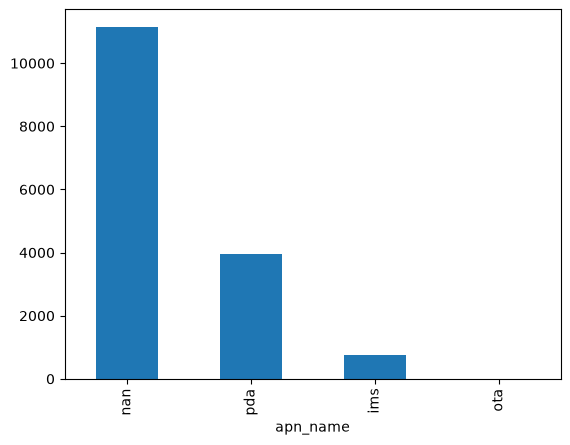

In [40]:
#Further explore those features which have missing values
faulty_features = faulty_feature_values()
if faulty_features:
    for col in faulty_features:
        data[col].value_counts(dropna=False).plot(kind="bar")
        plt.show()
        


Index(['step', 'rat_id', 'eci_nci', 'network', 'timestamp', 'latitude',
       'longitude', 'geometry_type', 'start_angle', 'end_angle',
       'outer_radius', 'inner_radius', 'cell_updated_flag',
       'device_interface_type', 'server', 'application_name', 'message_name',
       'apn_name'],
      dtype='str')


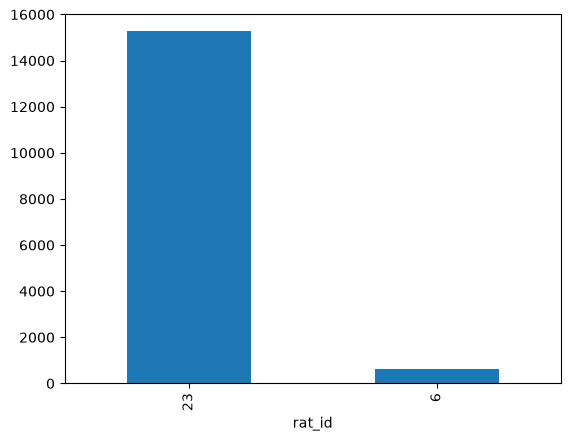

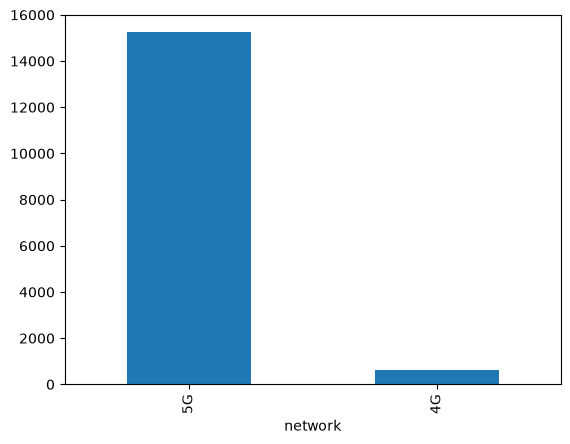

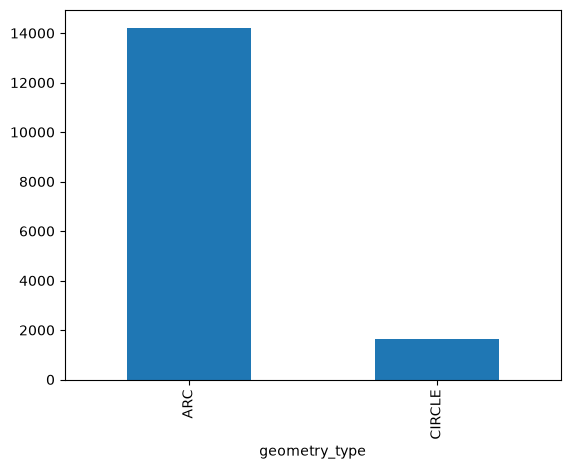

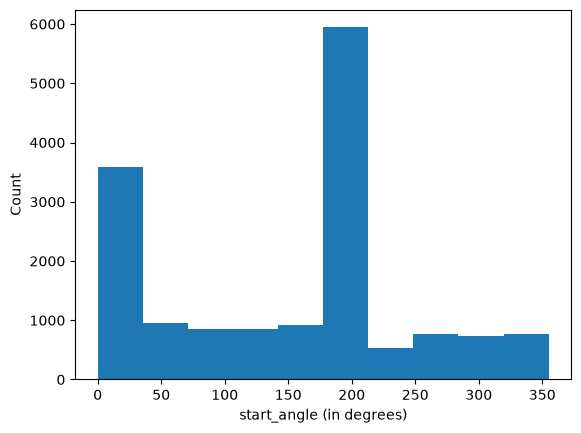

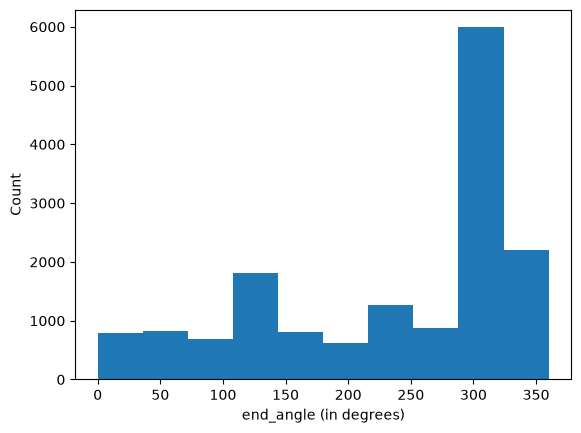

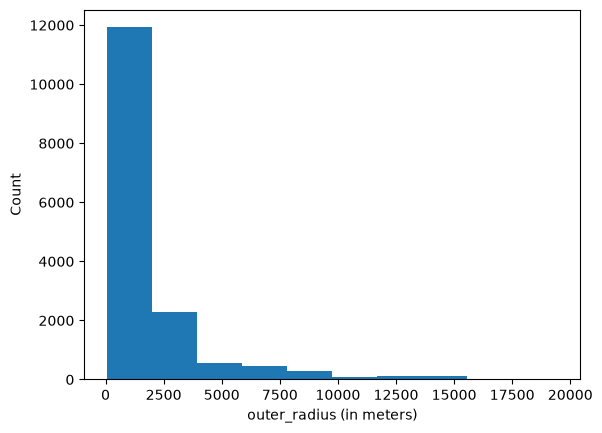

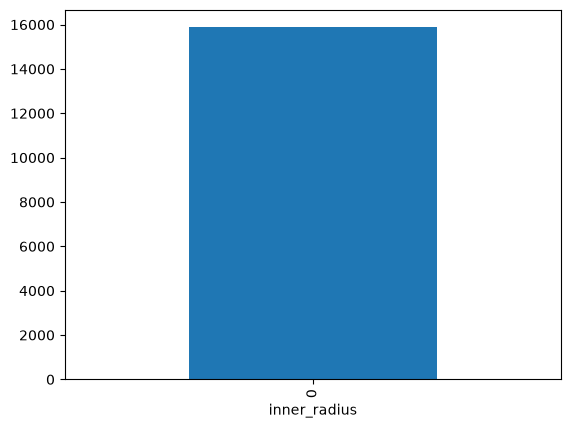

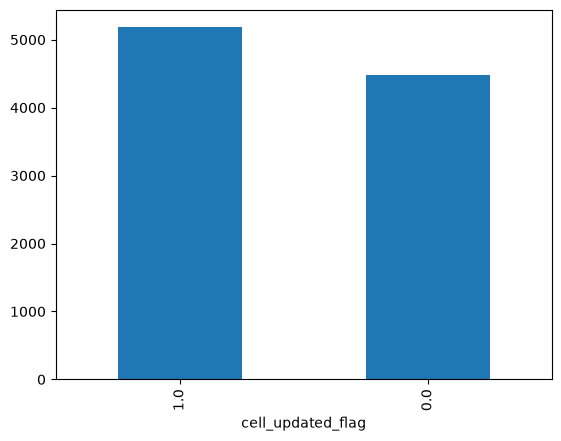

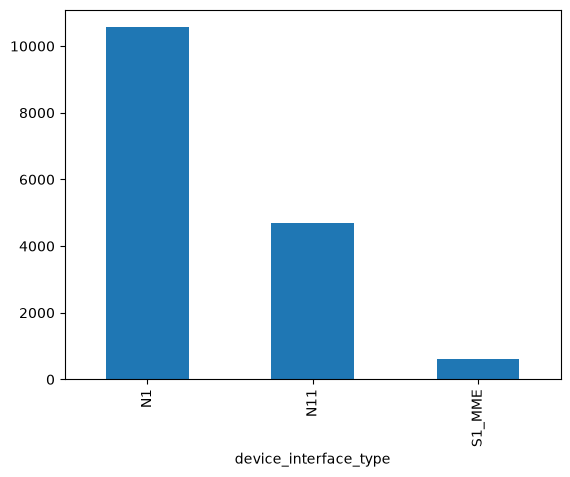

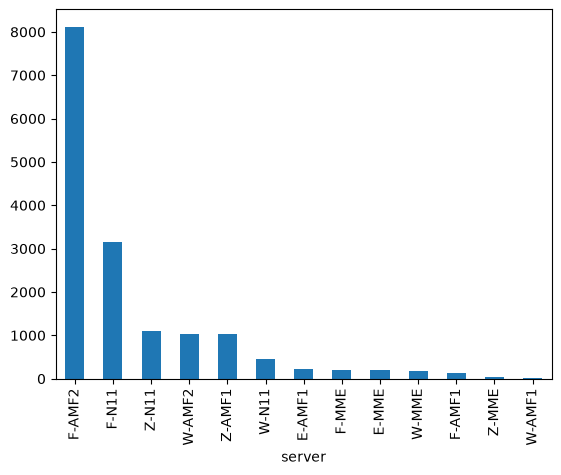

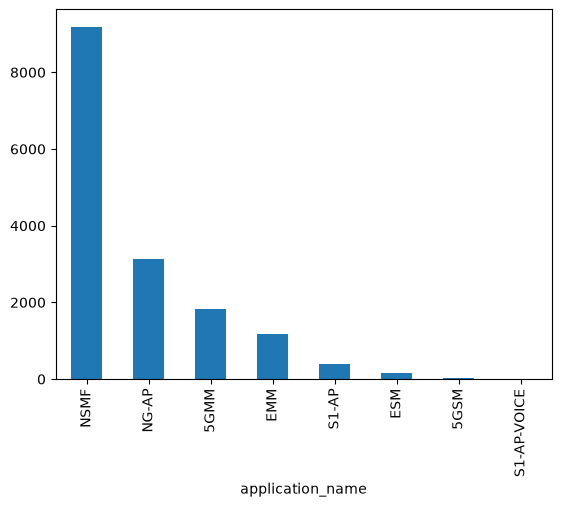

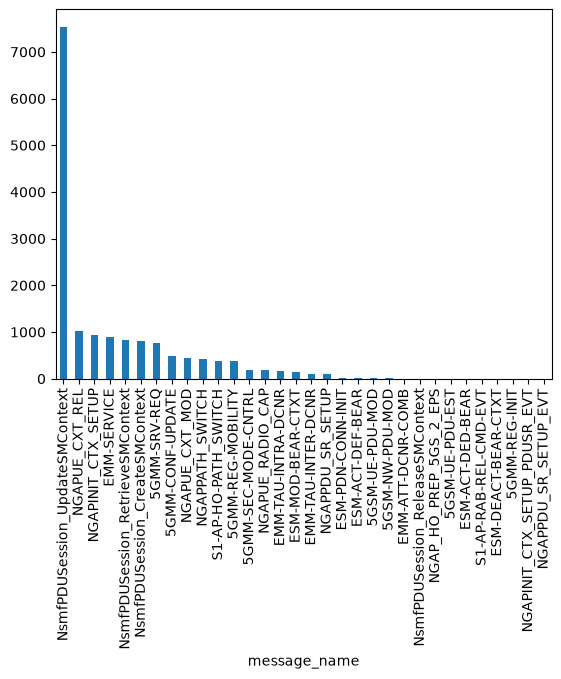

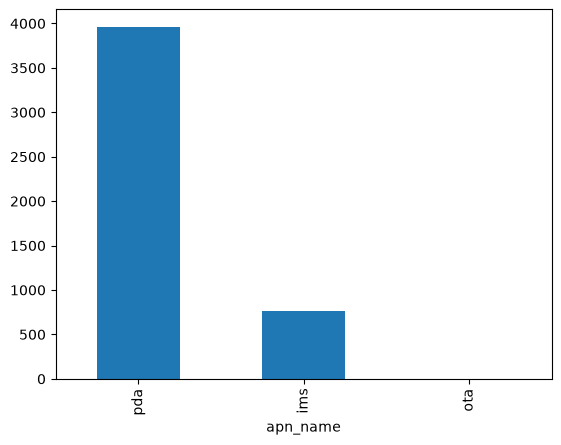

In [ ]:
#Plotting each feature value_counts
print(data.columns)

features = ["rat_id", "network", "geometry_type", "start_angle", 
            "end_angle", "outer_radius", "inner_radius", "cell_updated_flag",
            "device_interface_type", "server", "application_name", "message_name", "apn_name"] 

#exluded features from plotting: step, eci_nci, timestamp, latitude, longitude
metrics = {"start_angle" : "in degrees", "end_angle" : "in degrees", "outer_radius" : "in meters"}
for col in features:
    #special treatment for certain features
    if col in set(["start_angle", "end_angle", "outer_radius"]):
        plt.hist(x=data[col], bins=10)
        plt.xlabel(f"{col} ({metrics[col]})")
        plt.ylabel("Count")
        plt.show()
   
    else:
        data[col].value_counts().plot(kind="bar")
        plt.show()
    

